# 04 — Görüntü Modeli: YOLOv8n ile Alev ve Duman Tespiti (D-Fire)

**Amaç:** Kamera karesinde alev ve duman bulan bir nesne tespit modeli eğitmek, **test setinde** ölçmek ve `src/vision.py` üzerinden sisteme bağlamak.

**Akış:** kurulum → eğitim (50 epoch, 416 px, YOLOv8n) → sınıf numaralarının doğrulanması → test seti ölçümü (mAP@0.5, sınıf bazlı AP, P, R) → 200 yangınsız görüntüde yanlış alarm ölçümü + hata analizi → 200 yangınlı test görüntüsünde yakalama oranı.

> ⚠️ **Önemli düzeltme (sınıf adları):** D-Fire etiketlerinde **0 = duman, 1 = alev**. Eğitimdeki `dfire.yaml` dosyasında adlar ters yazılmıştı (`names: ['fire', 'smoke']`). Bu yüzden eğitim çıktısında "fire" yazan satır aslında **duman**, "smoke" yazan satır aslında **alev**dir. Bölüm 3'te görselle doğrulandı; Bölüm 4'te model dosyasındaki adlar düzeltildi. Modelin kendisi (ağırlıklar) doğrudur; yalnızca adlar ters yazılmıştı, yeniden eğitim gerekmez.

## 1. Kurulum ve veri

In [3]:
# 1. Ultralytics kütüphanesini yükle (YOLO için)
!pip install ultralytics

# 2. Kontrol et
import ultralytics
print("Ultralytics versiyon:", ultralytics.__version__)

Ultralytics versiyon: 8.4.191


In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

# DFire klasörü Drive'da var mı? (Drive'ın tamamını listelemiyoruz; yalnızca gereken klasöre bakıyoruz)
dfire = '/content/drive/MyDrive/DFire'
print("DFire klasörü var mı?", os.path.exists(dfire))
print("İçeriği:", os.listdir(dfire) if os.path.exists(dfire) else "-")

In [7]:
import os

# DFire içindeki data klasörü
base_path = '/content/drive/MyDrive/DFire/data'

print("Data klasörü içeriği:")
print(os.listdir(base_path))

# Train, val, test var mı?
for split in ['train', 'val', 'test']:
    split_path = os.path.join(base_path, split)
    if os.path.exists(split_path):
        print(f"\n✅ {split} klasörü var")
        print(f"   İçindekiler: {os.listdir(split_path)}")
    else:
        print(f"\n❌ {split} klasörü yok!")

Data klasörü içeriği:
['val', 'test', 'train']

✅ train klasörü var
   İçindekiler: ['labels', 'images', 'labels.cache']

✅ val klasörü var
   İçindekiler: ['images', 'labels', 'labels.cache']

✅ test klasörü var
   İçindekiler: ['labels', 'images']


In [8]:
# Eğitimde kullanılan yaml (kayıt için olduğu gibi bırakıldı).
# NOT: names sırası TERS yazılmış; doğrusu ['smoke', 'fire'] (0 = duman, 1 = alev). Bkz. Bölüm 3.
import os

base_path = '/content/drive/MyDrive/DFire/data'

# YAML içeriği
yaml_content = f"""
path: {base_path}
train: {base_path}/train/images
val: {base_path}/val/images
test: {base_path}/test/images

nc: 2
names: ['fire', 'smoke']
"""

# YAML'ı kaydet
with open('/content/dfire.yaml', 'w') as f:
    f.write(yaml_content)

print("✅ dfire.yaml oluşturuldu!")
print("\nİçeriği:")
print(yaml_content)

# Kontrol et
print("Train images var mı?", os.path.exists(f'{base_path}/train/images'))
print("Val images var mı?", os.path.exists(f'{base_path}/val/images'))
print("Test images var mı?", os.path.exists(f'{base_path}/test/images'))

✅ dfire.yaml oluşturuldu!

İçeriği:

path: /content/drive/MyDrive/DFire/data
train: /content/drive/MyDrive/DFire/data/train/images
val: /content/drive/MyDrive/DFire/data/val/images
test: /content/drive/MyDrive/DFire/data/test/images

nc: 2
names: ['fire', 'smoke']

Train images var mı? True
Val images var mı? True
Test images var mı? True


## 2. Eğitim (YOLOv8n, 50 epoch, 416 px, batch 16, Colab T4)

Varsayılan veri artırmaları (yatay çevirme `fliplr=0.5`, renk `hsv_h/s/v`, `mosaic`) eğitimde zaten açıktı.

In [9]:
from ultralytics import YOLO
import torch

# GPU var mı kontrol et
print("GPU kullanılıyor mu?", torch.cuda.is_available())
print("GPU adı:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Yok")

# Modeli yükle
model = YOLO('yolov8n.pt')

# Eğitim başlat — SONUÇLAR DOĞRUDAN DRIVE'A KAYDEDİLİR
# Böylece bağlantı kopsa / oturum kapansa bile eğitilen model kaybolmaz
results = model.train(
    data='/content/dfire.yaml',
    epochs=50,
    imgsz=416,
    batch=16,
    name='fire_smoke_model',
    project='/content/drive/MyDrive/DFire/runs',
    device=0  # GPU kullan
)

print("✅ Eğitim tamamlandı!")
print("📁 Model ve grafikler Drive'da: /content/drive/MyDrive/DFire/runs/fire_smoke_model")

GPU kullanılıyor mu? True
GPU adı: Tesla T4
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dfire.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fire_smoke_model, nbs=64,

### Doğrulama (val) seti sonuçları — en iyi ağırlıklar (best.pt)

Aşağıdaki değerler **val** setine (3.101 görüntü) aittir; test seti sonuçları Bölüm 5'tedir. Eğitim çıktısındaki sınıf adları ters olduğu için burada doğru adlarla yazılmıştır.

| Sınıf | Görüntü | Kutu | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|---|---|
| Tümü | 3101 | 3932 | 0,759 | 0,675 | 0,740 | 0,425 |
| **Duman** (sınıf 0; çıktıda "fire" yazıyor) | 1550 | 1756 | 0,797 | 0,759 | 0,816 | 0,505 |
| **Alev** (sınıf 1; çıktıda "smoke" yazıyor) | 879 | 2176 | 0,720 | 0,591 | 0,665 | 0,346 |

Not: mAP bir "doğruluk" (accuracy) değildir; kutuların yeri ve sınıfı birlikte değerlendirilerek hesaplanan ortalama kesinliktir.

## 3. Sınıf numaralarının doğrulanması (0 = ? , 1 = ?)

Etiket dosyasındaki kutuları görüntünün üzerine çiziyoruz: kırmızı = sınıf 0, mavi = sınıf 1.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

base = '/content/drive/MyDrive/DFire/data/test'
ad = 'WEB11799'   # içinde hem duman hem alev olan bir test görüntüsü
img = Image.open(f'{base}/images/{ad}.jpg')
W, H = img.size

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(img)
for satir in open(f'{base}/labels/{ad}.txt'):
    s, x, y, w, h = satir.split()
    s, x, y, w, h = int(s), float(x)*W, float(y)*H, float(w)*W, float(h)*H
    renk = 'red' if s == 0 else 'blue'
    ax.add_patch(patches.Rectangle((x-w/2, y-h/2), w, h, edgecolor=renk, facecolor='none', linewidth=2))
    ax.text(x-w/2, y-h/2, f'sınıf {s}', color='white', bbox=dict(facecolor=renk, alpha=0.7))
ax.set_title(f'{ad}: kırmızı = sınıf 0, mavi = sınıf 1')
ax.axis('off')
plt.savefig('sinif_dogrulama.png', bbox_inches='tight')
plt.show()

**Sonuç:** Kırmızı (sınıf 0) kutu görüntünün neredeyse tamamını kaplayan **duman bulutunu**, mavi (sınıf 1) küçük kutular yamaçtaki turuncu **alev** hattını işaretliyor. Yani **0 = duman, 1 = alev**.

Bu, D-Fire'ın resmî istatistikleriyle de tutarlıdır: duman daha çok görüntüde ama görüntü başına az kutuyla (≈1,1), alev daha az görüntüde ama görüntü başına çok kutuyla (≈2,5) etiketlenmiştir. Val setinde "fire" adlı sınıf 1550 görüntüde 1756 kutu (1,13/görüntü), "smoke" adlı sınıf 879 görüntüde 2176 kutu (2,48/görüntü) ile görülüyor; yani adlar terstir.

## 4. Model dosyasındaki sınıf adlarını düzeltme

Ağırlıklar değişmez; yalnızca dosyanın içindeki ad sözlüğü düzeltilir. Düzeltilmiş dosya Drive'daki ortak **Modeller** klasörüne `fire_smoke.pt` adıyla yüklenmelidir. (`src/vision.py` adlara değil sınıf numarasına baktığı için eski dosyayla da doğru çalışır.)

In [ ]:
import torch
from ultralytics import YOLO

eski = '/content/drive/MyDrive/YanginProjesi/modeller/fire_smoke.pt'
yeni = '/content/drive/MyDrive/YanginProjesi/modeller/fire_smoke_duzeltilmis.pt'

ck = torch.load(eski, map_location='cpu', weights_only=False)
print('Önce :', ck['model'].names)
ck['model'].names = {0: 'smoke', 1: 'fire'}
if ck.get('ema') is not None:
    ck['ema'].names = {0: 'smoke', 1: 'fire'}
torch.save(ck, yeni)

model = YOLO(yeni)
print('Sonra:', model.names)   # {0: 'smoke', 1: 'fire'} olmalı

## 5. Test seti ölçümü (modelin hiç görmediği D-Fire resmî test bölmesi)

Adları doğru yazılmış yeni bir yaml ile test setinde `model.val(split='test')` çalıştırılır. Bu hücre **yalnızca bir kez** çalıştırılır; sonuç rapora girer.

In [ ]:
base_path = '/content/drive/MyDrive/DFire/data'
with open('/content/dfire_dogru.yaml', 'w') as f:
    f.write(f'''path: {base_path}
train: {base_path}/train/images
val: {base_path}/val/images
test: {base_path}/test/images
nc: 2
names: ['smoke', 'fire']
''')

m = model.val(data='/content/dfire_dogru.yaml', split='test', imgsz=416, batch=16, plots=True,
              project='/content/drive/MyDrive/DFire/runs', name='test_degerlendirme')

print('TEST SETİ')
print(f'  mAP@0.5      : {m.box.map50:.3f}')
print(f'  mAP@0.5:0.95 : {m.box.map:.3f}')
print(f'  Precision    : {m.box.mp:.3f}')
print(f'  Recall       : {m.box.mr:.3f}')
for i, ad in model.names.items():
    print(f'  {ad:5s} AP@0.5 = {m.box.ap50[i]:.3f}   P = {m.box.p[i]:.3f}   R = {m.box.r[i]:.3f}')

### Test seti sonuçları (yukarıdaki hücre çalıştırılınca doldurulacak)

| Sınıf | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|
| Tümü | ___ | ___ | ___ | ___ |
| Duman | ___ | ___ | ___ | — |
| Alev | ___ | ___ | ___ | — |

Grafikler (PR eğrisi, karışıklık matrisi) Drive'da `DFire/runs/test_degerlendirme/` klasörüne kaydedilir.

## 6. Yanlış alarm ölçümü: 200 yangınsız test görüntüsü

Etiket dosyası boş olan (alev ve duman içermeyen) test görüntülerinden **rastgele** 200 tanesi seçilir (art arda gelen kareler birbirinin neredeyse kopyası olduğu için sıralı seçim yapılmaz). Sistemde kullanılan güven eşiği `0.25`'tir (`src/vision.py`); karşılaştırma için `0.5` de ölçülür. Ayrıca, kameranın tek başına ŞÜPHELİ ürettiği durum (en yüksek güven ≥ 0,60) sayılır.

In [ ]:
import os, random
import matplotlib.pyplot as plt

test_img = '/content/drive/MyDrive/DFire/data/test/images'
test_lbl = '/content/drive/MyDrive/DFire/data/test/labels'

def etiket_bos_mu(ad):
    yol = os.path.join(test_lbl, os.path.splitext(ad)[0] + '.txt')
    return (not os.path.exists(yol)) or os.path.getsize(yol) == 0

tumu = sorted(os.listdir(test_img))
negatifler = [f for f in tumu if etiket_bos_mu(f)]
pozitifler = [f for f in tumu if not etiket_bos_mu(f)]
print('Test seti:', len(tumu), 'görüntü |', len(negatifler), 'yangınsız |', len(pozitifler), 'yangınlı')

random.seed(42)
neg200 = random.sample(negatifler, 200)

sonuclar = []   # (dosya, en yüksek güven, sınıf adı)
for f in neg200:
    r = model.predict(os.path.join(test_img, f), conf=0.05, imgsz=416, verbose=False)[0]
    if len(r.boxes):
        i = int(r.boxes.conf.argmax())
        sonuclar.append((f, float(r.boxes.conf[i]), model.names[int(r.boxes.cls[i])]))
    else:
        sonuclar.append((f, 0.0, '-'))

for esik in [0.25, 0.5, 0.6]:
    yanlis = [s for s in sonuclar if s[1] >= esik]
    print(f'Güven eşiği {esik}: {len(yanlis)}/200 görüntüde yanlış alarm (%{len(yanlis)/2:.1f})')

# En yüksek güvenli 10 yanlış alarmı kaydet (hata analizi için)
en_kotu = sorted([s for s in sonuclar if s[1] >= 0.25], key=lambda s: -s[1])[:10]
if en_kotu:
    fig, axes = plt.subplots(2, 5, figsize=(25, 9))
    for ax in axes.flatten(): ax.axis('off')
    for ax, (f, g, ad) in zip(axes.flatten(), en_kotu):
        r = model.predict(os.path.join(test_img, f), conf=0.25, imgsz=416, verbose=False)[0]
        ax.imshow(r.plot()[:, :, ::-1])
        ax.set_title(f'{f}  {ad} {g:.2f}')
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/DFire/runs/yanlis_alarmlar.png')
    plt.show()
print('Yanlış alarm veren görüntüler:', [(f, round(g, 2), ad) for f, g, ad in en_kotu])

### Yanlış alarm analizi (yukarıdaki hücre çalıştırılınca doldurulacak)

| Güven eşiği | Yanlış alarm (200 yangınsız görüntü) |
|---|---|
| 0,25 (sistemde kullanılan) | ___ / 200 |
| 0,50 | ___ / 200 |
| 0,60 (kamera tek başına ŞÜPHELİ) | ___ / 200 |

Yanlış alarm veren görüntüler (`yanlis_alarmlar.png`) — her biri için tek cümlelik neden:

| # | Görüntü | Sanılan | Güven | Neden (tek cümle) |
|---|---|---|---|---|
| 1 | ___ | ___ | ___ | ___ |
| 2 | ___ | ___ | ___ | ___ |

(Hiç yanlış alarm yoksa: "200 yangınsız görüntünün hiçbirinde 0,25 güvenin üzerinde tespit yapılmadı." yazılır.)

## 7. Yakalama oranı: 200 yangınlı test görüntüsü

Görüntü düzeyinde ölçüm: görüntüde en az bir alev ya da duman kutusu bulunduysa "yakalandı" sayılır.

In [ ]:
random.seed(42)
poz200 = random.sample(pozitifler, 200)
yakalanan = {0.25: 0, 0.5: 0}
kacirilanlar = []
for f in poz200:
    r = model.predict(os.path.join(test_img, f), conf=0.25, imgsz=416, verbose=False)[0]
    g = float(r.boxes.conf.max()) if len(r.boxes) else 0.0
    for esik in yakalanan:
        yakalanan[esik] += g >= esik
    if g < 0.25:
        kacirilanlar.append(f)
for esik, n in yakalanan.items():
    print(f'Güven eşiği {esik}: {n}/200 yangınlı görüntü yakalandı (görüntü düzeyinde recall = {n/200:.2f})')
print('Kaçırılanlar (0.25):', kacirilanlar)

| Güven eşiği | Yakalanan (200 yangınlı test görüntüsü) |
|---|---|
| 0,25 | ___ / 200 |
| 0,50 | ___ / 200 |

## Ek — İlk denemeler (rapora girmez)

> ⚠️ Aşağıdaki hücreler ilk denemelerdir ve **rapor için kullanılmaz**:
> - "İlk 100 test görüntüsü" ölçümünde seçilen 100 görüntünün hepsi yangınsızdı ve art arda gelen karelerdi (aynı kamera), bu yüzden temsil edici değildir → yerine Bölüm 6.
> - "%91 yakalama" ölçümü **eğitim (train) görüntüleriyle** yapıldı; model bu görüntüleri eğitimde gördüğü için geçerli bir test değildir → yerine Bölüm 5 ve 7.

In [4]:
from ultralytics import YOLO
import os

# Drive bağlı mı kontrol et
if not os.path.exists('/content/drive/MyDrive/DFire'):
    from google.colab import drive
    drive.mount('/content/drive')

# Modeli bul
model_path = '/content/drive/MyDrive/DFire/runs/fire_smoke_model/weights/best.pt'
print("Model var mı?", os.path.exists(model_path))

# Eğer yoksa last.pt dene
if not os.path.exists(model_path):
    model_path = '/content/drive/MyDrive/DFire/runs/fire_smoke_model/weights/last.pt'
    print("Last model var mı?", os.path.exists(model_path))

# Modeli yükle
model = YOLO(model_path)
print("✅ Model yüklendi!")

Mounted at /content/drive
Model var mı? True
✅ Model yüklendi!


Yangınlı görüntü: /content/drive/MyDrive/DFire/data/train/images/AoF00001.jpg

image 1/1 /content/drive/MyDrive/DFire/data/train/images/AoF00001.jpg: 256x416 1 smoke, 7.2ms
Speed: 1.2ms preprocess, 7.2ms inference, 25.3ms postprocess per image at shape (1, 3, 256, 416)


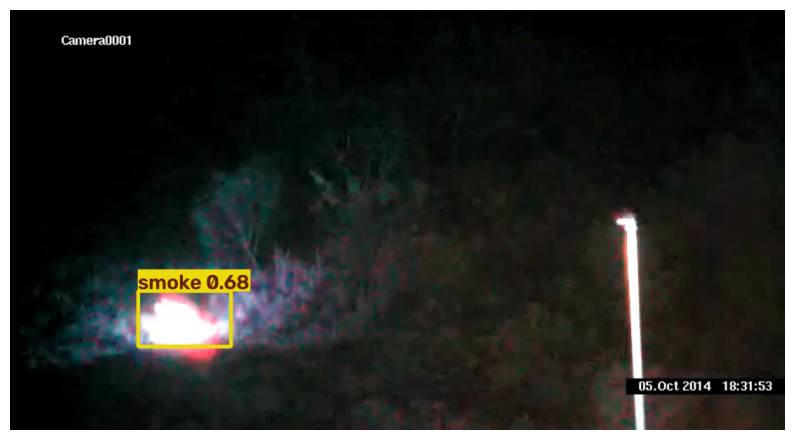

Tespit edilen: [('smoke', 0.6812565922737122)]


In [9]:
import os
import matplotlib.pyplot as plt

# Train klasöründen yangınlı bir görüntü seç (test klasöründe yangınlı olmayabilir)
train_dir = '/content/drive/MyDrive/DFire/data/train/images'
label_dir = '/content/drive/MyDrive/DFire/data/train/labels'

# Yangınlı görüntü bul (etiketi olan ilk görüntü)
yanginli_img = None
for f in sorted(os.listdir(train_dir))[:100]:  # İlk 100'de ara
    label_file = f.replace('.jpg', '.txt')
    label_path = os.path.join(label_dir, label_file)
    if os.path.exists(label_path):
        with open(label_path, 'r') as lf:
            if len(lf.readlines()) > 0:  # Etiket var = yangın/duman var
                yanginli_img = os.path.join(train_dir, f)
                break

print("Yangınlı görüntü:", yanginli_img)

# Tahmin yap
results = model.predict(yanginli_img, conf=0.5)

# Sonucu göster
for r in results:
    plt.figure(figsize=(10, 8))
    plt.imshow(r.plot()[:, :, ::-1])  # BGR -> RGB
    plt.axis('off')
    plt.savefig('yangin_tespit.png')
    plt.show()

    print("Tespit edilen:", [(model.names[int(b.cls)], float(b.conf)) for b in r.boxes])

In [10]:
import shutil
import os

# Hedef klasör
hedef_klasor = '/content/drive/MyDrive/YanginProjesi/modeller'
os.makedirs(hedef_klasor, exist_ok=True)

# Modeli kopyala
kaynak = '/content/drive/MyDrive/DFire/runs/fire_smoke_model/weights/best.pt'
hedef = os.path.join(hedef_klasor, 'fire_smoke.pt')

shutil.copy(kaynak, hedef)
print(f"✅ Model kopyalandı: {hedef}")
print(f"📁 Boyut: {os.path.getsize(hedef) / 1024 / 1024:.1f} MB")

✅ Model kopyalandı: /content/drive/MyDrive/YanginProjesi/modeller/fire_smoke.pt
📁 Boyut: 6.2 MB



image 1/1 /content/drive/MyDrive/DFire/data/test/images/AoF06733.jpg: 256x416 (no detections), 16.7ms
Speed: 1.5ms preprocess, 16.7ms inference, 0.7ms postprocess per image at shape (1, 3, 256, 416)

image 1/1 /content/drive/MyDrive/DFire/data/test/images/AoF06734.jpg: 256x416 (no detections), 7.2ms
Speed: 1.0ms preprocess, 7.2ms inference, 0.6ms postprocess per image at shape (1, 3, 256, 416)

image 1/1 /content/drive/MyDrive/DFire/data/test/images/AoF06735.jpg: 256x416 (no detections), 6.9ms
Speed: 1.1ms preprocess, 6.9ms inference, 0.6ms postprocess per image at shape (1, 3, 256, 416)

image 1/1 /content/drive/MyDrive/DFire/data/test/images/AoF06736.jpg: 256x416 (no detections), 6.9ms
Speed: 1.0ms preprocess, 6.9ms inference, 0.6ms postprocess per image at shape (1, 3, 256, 416)

image 1/1 /content/drive/MyDrive/DFire/data/test/images/AoF06737.jpg: 256x416 (no detections), 7.3ms
Speed: 1.2ms preprocess, 7.3ms inference, 0.5ms postprocess per image at shape (1, 3, 256, 416)


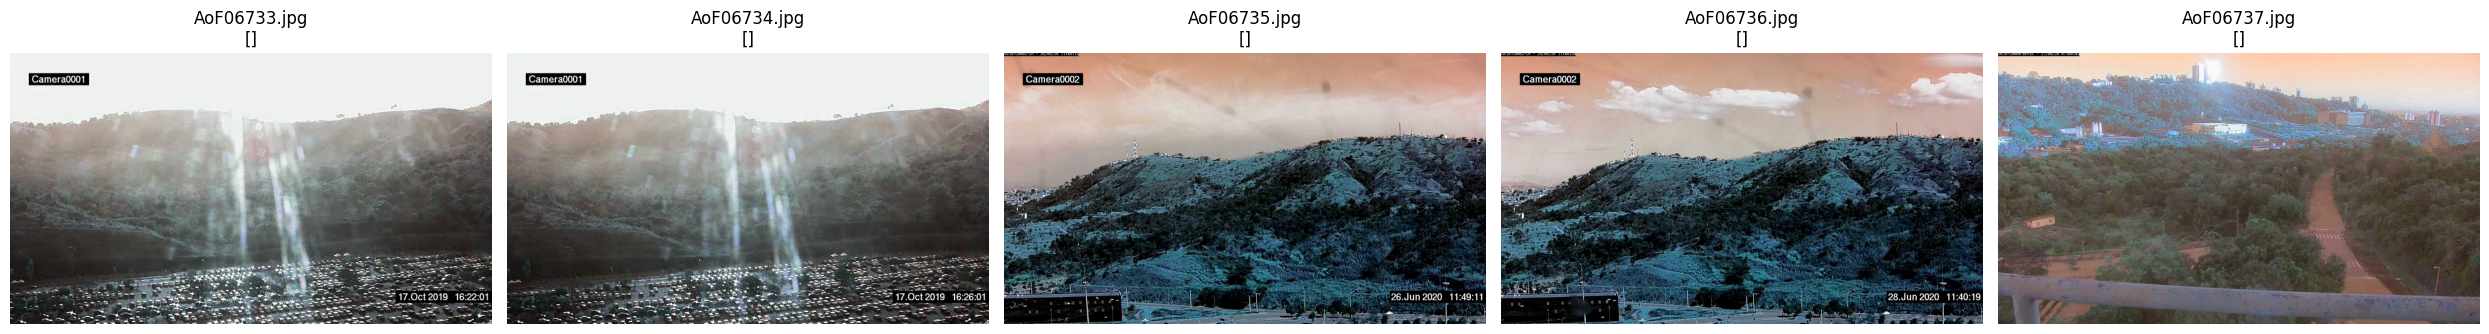

In [11]:
import os
import matplotlib.pyplot as plt

# Test klasöründen birkaç görüntü daha dene
test_dir = '/content/drive/MyDrive/DFire/data/test/images'
test_images = sorted(os.listdir(test_dir))[10:15]  # 10-15 arası dosyalar

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for i, img_name in enumerate(test_images):
    img_path = os.path.join(test_dir, img_name)
    results = model.predict(img_path, conf=0.5)

    for r in results:
        axes[i].imshow(r.plot()[:, :, ::-1])  # BGR -> RGB
        axes[i].set_title(f"{img_name[:15]}\n{[(model.names[int(b.cls)], round(float(b.conf),2)) for b in r.boxes]}")
        axes[i].axis('off')

plt.tight_layout()
plt.savefig('coklu_test.png')
plt.show()

In [13]:
import os
from ultralytics import YOLO

# Modeli yükle
model = YOLO('/content/drive/MyDrive/YanginProjesi/modeller/fire_smoke.pt')

# Test klasörü
test_dir = '/content/drive/MyDrive/DFire/data/test/images'
label_dir = '/content/drive/MyDrive/DFire/data/test/labels'

# İstatistikler
tp = 0  # Yangın var, model "var" dedi
fp = 0  # Yangın yok, model "var" dedi (yanlış alarm)
fn = 0  # Yangın var, model "yok" dedi (tehlikeli!)
tn = 0  # Yangın yok, model "yok" dedi

# İlk 100 test görüntüsünü değerlendir
test_files = sorted(os.listdir(test_dir))[:100]

for img_name in test_files:
    img_path = os.path.join(test_dir, img_name)
    label_path = os.path.join(label_dir, img_name.replace('.jpg', '.txt'))

    # Gerçek etiket
    gercek_yangin = os.path.exists(label_path) and os.path.getsize(label_path) > 0

    # Model tahmini
    results = model.predict(img_path, conf=0.5, verbose=False)
    tahmin_yangin = len(results[0].boxes) > 0

    # Karşılaştır
    if gercek_yangin and tahmin_yangin:
        tp += 1
    elif not gercek_yangin and tahmin_yangin:
        fp += 1
    elif gercek_yangin and not tahmin_yangin:
        fn += 1
    else:
        tn += 1

print("="*50)
print("TEST SETİ PERFORMANSI (İlk 100 görüntü)")
print("="*50)
print(f"Doğru Pozitif (TP): {tp} - Yangın var, model yakaladı")
print(f"Yanlış Pozitif (FP): {fp} - Yangın yok, model 'var' dedi")
print(f"Yanlış Negatif (FN): {fn} - Yangın var, model 'yok' dedi ⚠️")
print(f"Doğru Negatif (TN): {tn} - Yangın yok, model 'yok' dedi")
print("="*50)
print(f"Precision: {tp/(tp+fp) if tp+fp>0 else 0:.2f}")
print(f"Recall: {tp/(tp+fn) if tp+fn>0 else 0:.2f}")
print(f"Accuracy: {(tp+tn)/100:.2f}")

TEST SETİ PERFORMANSI (İlk 100 görüntü)
Doğru Pozitif (TP): 0 - Yangın var, model yakaladı
Yanlış Pozitif (FP): 0 - Yangın yok, model 'var' dedi
Yanlış Negatif (FN): 0 - Yangın var, model 'yok' dedi ⚠️
Doğru Negatif (TN): 100 - Yangın yok, model 'yok' dedi
Precision: 0.00
Recall: 0.00
Accuracy: 1.00


In [14]:
import os
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/YanginProjesi/modeller/fire_smoke.pt')

# Train klasöründen yangınlı görüntüler seç (test setinde yangınlı az olabilir)
train_dir = '/content/drive/MyDrive/DFire/data/train/images'
label_dir = '/content/drive/MyDrive/DFire/data/train/labels'

# Yangınlı görüntüleri bul
yanginli_goruntuler = []
for f in sorted(os.listdir(train_dir)):
    label_path = os.path.join(label_dir, f.replace('.jpg', '.txt'))
    if os.path.exists(label_path) and os.path.getsize(label_path) > 0:
        yanginli_goruntuler.append(f)
    if len(yanginli_goruntuler) >= 100:  # İlk 100 yangınlı
        break

print(f"Bulunan yangınlı görüntü: {len(yanginli_goruntuler)}")

# Test et
tp = 0  # Yakaladı
fn = 0  # Kaçırdı

for img_name in yanginli_goruntuler:
    img_path = os.path.join(train_dir, img_name)
    results = model.predict(img_path, conf=0.5, verbose=False)

    if len(results[0].boxes) > 0:
        tp += 1
    else:
        fn += 1

print("="*50)
print("YANGINLI GÖRÜNTÜLERDE TEST (100 görüntü)")
print("="*50)
print(f"Yakalanan (TP): {tp}")
print(f"Kaçırılan (FN): {fn} ⚠️")
print(f"Recall: {tp/(tp+fn):.2f} (%{tp/(tp+fn)*100:.0f})")

Bulunan yangınlı görüntü: 100
YANGINLI GÖRÜNTÜLERDE TEST (100 görüntü)
Yakalanan (TP): 91
Kaçırılan (FN): 9 ⚠️
Recall: 0.91 (%91)


### Hata analizi: kaçırılan görüntüler (eğitim görüntüleri üzerinde, ilk deneme)

100 eğitim görüntüsünden 9'u 0,5 güven eşiğinde kaçırıldı. İncelenen örnekler (her görüntü tek bir kategoride):

1. **Mesafe / küçük alan (4):** AoF01029, AoF01030, AoF03567, AoF03568 — yangın çok uzakta, görüntüde küçük alan kaplıyor.
2. **Sis / bulut (2):** AoF01166 (sis), AoF03570 (bulutlu gökyüzü) — duman sis veya bulutla karışıyor.
3. **Parlama / yansıma (1):** AoF00002 — güneş parlaması; etiket hatası da olabilir.
4. **Erken aşama (1):** AoF03797 — yangın başlangıç aşamasında, belirti zayıf.
5. **Diğer (1):** dokuzuncu görüntünün adı hücre çıktısından eklenmeli.

**Çözüm önerileri:** daha büyük model (YOLOv8s/m), daha uzun eğitim (**50 yerine 100 epoch**), daha büyük görüntü boyutu (416 yerine 640; küçük/uzak dumanlar için) ve sensörle füzyon (bu açığı sistem düzeyinde kapatır). Renk ve yatay çevirme artırmaları eğitimde zaten varsayılan olarak açıktı.

In [15]:
import os
import matplotlib.pyplot as plt

# Kaçırılan yangınları bul
kaçırılanlar = []
for img_name in yanginli_goruntuler:
    img_path = os.path.join(train_dir, img_name)
    results = model.predict(img_path, conf=0.5, verbose=False)

    if len(results[0].boxes) == 0:  # Kaçırılan
        kaçırılanlar.append(img_name)

print(f"Kaçırılan yangın sayısı: {len(kaçırılanlar)}")

# İlk 9'unu göster
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, img_name in enumerate(kaçırılanlar[:9]):
    img_path = os.path.join(train_dir, img_name)
    img = plt.imread(img_path)
    axes[i].imshow(img)
    axes[i].set_title(f"Kaçırılan: {img_name[:20]}")
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('kacirilan_yanginlar.png')
plt.show()
print("Kaçırılan yangınlar kaydedildi: kacirilan_yanginlar.png")

Output hidden; open in https://colab.research.google.com to view.

In [16]:
import shutil

# Kaynak (Colab'ın geçici dizini)
kaynak = '/content/kacirilan_yanginlar.png'

# Hedef (Drive'daki grafikler klasörü)
hedef = '/content/drive/MyDrive/YanginProjesi/belgeler/grafikler/kacirilan_yanginlar.png'

# Klasör yoksa oluştur
import os
os.makedirs(os.path.dirname(hedef), exist_ok=True)

# Kopyala
shutil.copy(kaynak, hedef)
print(f"✅ Kaydedildi: {hedef}")

✅ Kaydedildi: /content/drive/MyDrive/YanginProjesi/belgeler/grafikler/kacirilan_yanginlar.png
